# Kernel ICL transience: paper figures

Loads a results pickle written by `rf_transience_closed_form.ipynb` (`rf_transience_closed_*.pkl` in
`RESULTPATH`) and plots the measured test error against $n_\mathrm{train}$ at a fixed task diversity $T$,
with the dMMSE and Ridge oracles as horizontal lines.

The curve is the mean over trials at the ID-validation-chosen ridge (`record["curve"]`), with a $\pm 1$
standard deviation band across trials (none with one trial); the oracles are the trial means of
`record["oracles"]`. Set `SIDES = ("ood", "id")` for OOD and ID side by side.
Several pickles can be overlaid through `RUNS`; the oracle lines then come from the first one.

## Colab setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os, subprocess

GIT_USER = "JoeyTurn"
GIT_REPO = "kernels_can_icl"
REPO_DIR = f"/content/{GIT_REPO}"

if not os.path.exists(REPO_DIR):
    r = subprocess.run(["git", "clone",
                        f"https://github.com/{GIT_USER}/{GIT_REPO}.git", REPO_DIR],
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr)
else:
    # Re-running the cell pulls latest changes instead of failing on "already exists"
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)

sys.path.insert(0, REPO_DIR)
sys.path.insert(0, f"{REPO_DIR}/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

if not os.path.exists("/content/expt-core"):
    subprocess.run(["git", "clone", "https://github.com/dkarkada/expt-core.git",
                    "/content/expt-core"], check=True)

sys.path.insert(0, "/content/expt-core")
from misc import rcsetup
rcsetup()

Mounted at /content/drive
GitHub PAT: ··········


In [2]:
import os, sys, glob, pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker

if os.path.exists("/content/kernels_can_icl"):
    # Colab: re-add the paths in case the runtime was restarted after the setup cell
    for p in ("/content/kernels_can_icl", "/content/kernels_can_icl/expts/rf_scaling", "/content/expt-core"):
        if p not in sys.path:
            sys.path.insert(0, p)
    RESULTPATH = os.environ.get("RESULTPATH", "/content/drive/MyDrive/results")
else:
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    sys.path.insert(0, str(ROOT.parent / "expt-core"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")

try:
    from misc import rcsetup
    rcsetup()
except ImportError:                     # the same settings as expt-core's misc.rcsetup
    plt.rc("figure", dpi=120, facecolor=(1, 1, 1))
    plt.rc("font", family="stixgeneral", size=12)
    plt.rc("axes", facecolor=(1, .99, .95), titlesize=12)
    plt.rc("mathtext", fontset="cm")
    plt.rc("pdf", fonttype=42)
    plt.rc("ps", fonttype=42)
print("RESULTPATH:", RESULTPATH)

RESULTPATH: /content/drive/MyDrive/results


In [3]:
import pickle
PATH = "/content/drive/MyDrive/results/rf_transience_closed_d4p4_P61440_w1.5_T8.pkl"   # the earlier run
for r in pickle.load(open(PATH, "rb"))["records"]:
    if r["T"] == 8:
        print(f"trial {r['trial']}")
        for c in r["curve"]:
            if c["n"] >= 2**14:
                print(f"  n={c['n']:>9,}  ridge {c['ridge_rel']:.1e} = {c['ridge_rel'] / c['kappa0']:g} x kappa0   OOD {c['ood']:.3f}")

trial 0
  n=   16,384  ridge 1.5e-08 = 3 x kappa0   OOD 0.824
  n=   32,768  ridge 4.0e-09 = 3 x kappa0   OOD 0.790
  n=   65,536  ridge 1.4e-09 = 3 x kappa0   OOD 0.748
  n=  100,000  ridge 8.2e-10 = 3 x kappa0   OOD 0.725
  n=  131,072  ridge 6.3e-10 = 3 x kappa0   OOD 0.714
  n=  150,000  ridge 5.7e-10 = 3 x kappa0   OOD 0.709
  n=  175,000  ridge 5.1e-10 = 3 x kappa0   OOD 0.705
  n=  200,000  ridge 4.6e-10 = 3 x kappa0   OOD 0.709
  n=  225,000  ridge 1.4e-10 = 1 x kappa0   OOD 0.811
  n=  250,000  ridge 1.4e-10 = 1 x kappa0   OOD 0.814
trial 1
  n=   16,384  ridge 1.3e-08 = 3 x kappa0   OOD 0.860
  n=   32,768  ridge 3.6e-09 = 3 x kappa0   OOD 0.819
  n=   65,536  ridge 1.2e-09 = 3 x kappa0   OOD 0.753
  n=  100,000  ridge 7.2e-10 = 3 x kappa0   OOD 0.725
  n=  131,072  ridge 5.6e-10 = 3 x kappa0   OOD 0.710
  n=  150,000  ridge 5.0e-10 = 3 x kappa0   OOD 0.703
  n=  175,000  ridge 4.5e-10 = 3 x kappa0   OOD 0.695
  n=  200,000  ridge 4.1e-10 = 3 x kappa0   OOD 0.692
  n=  225,00

## Settings

`RUNS` maps a legend label to a pickle path (absolute, or a file name inside `RESULTPATH`); `None`
picks the newest non-smoke `rf_transience_closed_*.pkl` there. One figure is drawn per T in `CURVE_TS`.

In [14]:
RUNS       = {"Analytical Random Feature Model": None}   # legend label -> pickle path; None = newest closed-form pickle
CURVE_TS   = [8]                    # one figure per T
SIDES      = ("ood", "id",)               # ("ood", "id") for OOD | ID side by side
YSCALE     = "log"                  # as in fig 2; "linear" also works
YLIM       = {}                     # e.g. {"ood": (0.25, 1.5)}; default fits the curves and the oracles
SD_BAND    = True                   # +/- 1 standard deviation across trials (none with 1 trial)
LEGEND_LOC = "lower left"           # a lower legend sits just above an oracle line along the bottom
FONTSIZE   = 15                     # tick labels and legend; axis labels +2, the T label +6
T_LABEL    = True                   # the in-plot "T=..." label
TOP_FREE   = 0.25                   # keep this much of the axis clear under the T label and legend
XLABEL     = r"Training Samples $n$"
PHASES       = True                   # shade the acquisition bands, in fig 1's wash and ink
PHASE_N      = (5e3,)                 # boundaries in n: one edge -> blue then green. None = no bands
PHASE_COLORS = ("#7fb3d5", "#7dcea0")              # blue, green (add "#f0b27a" for a third band)
PHASE_ALPHA, PHASE_DARKEN, PHASE_SAT, PHASE_EDGE_LW = 0.28, 0.78, 1.75, 1.2

In [15]:
def newest_pickle(resultpath, pattern):
    """Newest matching pickle, preferring full runs over _smoke ones."""
    paths = glob.glob(os.path.join(resultpath, pattern))
    if not paths:
        raise FileNotFoundError(f"no {pattern} in {resultpath}")
    full = [p for p in paths if "_smoke" not in os.path.basename(p)]
    return max(full or paths, key=os.path.getmtime)


def resolve(path, pattern):
    """A RUNS entry -> a file: None = the newest match in RESULTPATH, a bare name is looked up there."""
    path = path or newest_pickle(RESULTPATH, pattern)
    if not os.path.isabs(path) and not os.path.exists(path):
        path = os.path.join(RESULTPATH, path)
    return path


runs, metas = [], []
for label, path in RUNS.items():
    path = resolve(path, "rf_transience_closed_*.pkl")
    with open(path, "rb") as f:
        blob = pickle.load(f)
    meta, records = blob["meta"], blob["records"]
    runs.append((label, records))
    metas.append(meta)
    trials = {T: sum(r["T"] == T for r in records) for T in sorted({r["T"] for r in records})}
    ns = [c["n"] for r in records for c in r["curve"]]
    print(f"{label}: {os.path.basename(path)}")
    print(f"    trials per T {trials}   P={meta['P']:,}   width {meta['width_factor']}x median"
          f"   n {min(ns):,} .. {max(ns):,}")

META = metas[0]
TAG = f"d{META['config']['dim']}p{META['pairs']}{'_smoke' if META.get('smoke') else ''}"

Analytical Random Feature Model: rf_transience_closed_d4p4e0.05_P66440_w1.5_probe_abs1.00e-04.pkl
    trials per T {2: 2, 4: 3, 8: 3, 16: 3, 32: 2, 64: 1}   P=66,440   width 1.5x median   n 64 .. 2,097,152


## Figure

In [16]:
# figure 2's palette, in series order
STYLES = [("#0F3087", "o"), ("#6C63F0", "s"), ("#D97706", "^"), ("#C2185B", "D"), ("#2E7D32", "v")]
ORACLES = (("dmmse", "dMMSE Oracle", "#DC143C", 2.0), ("ridge", "Ridge Oracle", "black", 2.8))
SIDE_NAME = {"ood": "OOD", "id": "ID"}


def curve_stats(records, T, side, band=True):
    """(n, mean, sd) of the measured curve at task diversity T, over trials. sd is the sample standard
    deviation across trials (never the standard error); 0 with one trial or band=False."""
    recs = [r for r in records if r["T"] == T and r.get("curve")]
    ns = sorted({c["n"] for r in recs for c in r["curve"]})
    m, s = [], []
    for n in ns:
        v = np.array([c[side] for r in recs for c in r["curve"] if c["n"] == n], float)
        v = v[np.isfinite(v)]
        m.append(v.mean() if v.size else np.nan)
        s.append(v.std(ddof=1) if band and v.size > 1 else 0.0)
    return np.array(ns, float), np.array(m), np.array(s)


def oracle(records, T, key, side):
    """Trial mean of an oracle ('dmmse' or 'ridge') at task diversity T."""
    return float(np.mean([r["oracles"][f"{key}_{side}"] for r in records if r["T"] == T]))


def theory_curve(records, T, side):
    """(n, trial mean) of the theory curve record["pred"], or None if the records carry none."""
    preds = [r["pred"] for r in records if r["T"] == T and r.get("pred")]
    if not preds:
        return None
    n = np.asarray(preds[0]["n"], float)
    return n, np.mean([p[side] for p in preds if len(p[side]) == len(n)], 0)


def log_ticks(lo, hi, max_ticks=7):
    """Round tick values for a log axis: the finest of {1,1.2,1.5,2,3,4,5,6,8}, {1,2,3,5}, {1,2,5}, {1}
    per decade that puts at most max_ticks inside [lo, hi]."""
    decades = 10.0 ** np.arange(np.floor(np.log10(lo)), np.ceil(np.log10(hi)) + 1)
    for mant in ((1, 1.2, 1.5, 2, 3, 4, 5, 6, 8), (1, 2, 3, 5), (1, 2, 5), (1,)):
        vals = [float(f"{m * d:.6g}") for d in decades for m in mant]
        vals = [v for v in vals if lo <= v <= hi]
        if 2 <= len(vals) <= max_ticks:
            return vals
    return None


def default_ylim(ax, xys, yscale, top_free, x_from=0.38):
    """y-limits that fit everything drawn, raised if needed so the top `top_free` of the axis is
    clear of data right of x-fraction `x_from` -- where the T label and an upper-right legend sit.
    The x-limits must already be set (call after plotting)."""
    log = yscale == "log"
    ok = lambda y: np.isfinite(y) & (y > 0) if log else np.isfinite(y)
    ys = np.concatenate([y[ok(y)] for _, y in xys])
    if log:
        lo, hi = ys.min() / 1.1, ys.max() * 1.08
    else:
        pad = 0.06 * (ys.max() - ys.min())
        lo, hi = ys.min() - pad, ys.max() + pad
    x0, x1 = np.log10(ax.get_xlim())
    under = [y[ok(y) & ((np.log10(n) - x0) / (x1 - x0) >= x_from)] if n is not None else y[ok(y)]
             for n, y in xys]
    top = max((u.max() for u in under if u.size), default=None)
    if top is not None and 0 < top_free < 1:
        if log:
            hi = max(hi, lo * (top / lo) ** (1.0 / (1.0 - top_free)))
        else:
            hi = max(hi, lo + (top - lo) / (1.0 - top_free))
    return lo, hi



# --- fig 1's phase shading: one source colour per band -> a pale wash and a darker ink --------------
PHASE_COLORS_DEF = ("#7fb3d5", "#7dcea0")        # blue then green; add "#f0b27a" for a third band
PHASE_ALPHA_DEF, PHASE_DARKEN_DEF, PHASE_SAT_DEF, PHASE_EDGE_LW_DEF = 0.28, 0.78, 1.75, 1.2


def phase_inks(colors, alpha=PHASE_ALPHA_DEF, darken=PHASE_DARKEN_DEF, sat=PHASE_SAT_DEF):
    """(wash, ink) per band, as the phase diagram builds them: the ink is the source colour with its
    saturation multiplied and its value cut; the wash -- the panel fill -- is that ink over white."""
    import colorsys
    import matplotlib.colors as mcolors
    wash, ink = [], []
    for c in colors:
        h, sat0, val = colorsys.rgb_to_hsv(*mcolors.to_rgb(c))
        k = colorsys.hsv_to_rgb(h, min(1.0, sat0 * sat), val * darken)
        ink.append(k)
        wash.append(tuple(1 - alpha + alpha * ch for ch in k))
    return wash, ink


def phase_spans(edges, xlim):
    """[(lo, hi)] for each band, clipped to the axis."""
    inner = [e for e in edges if xlim[0] < e < xlim[1]]
    bounds = [xlim[0]] + sorted(inner) + [xlim[1]]
    return list(zip(bounds[:-1], bounds[1:]))


def draw_phases(ax, spans, wash, ink=None, edge_lw=PHASE_EDGE_LW_DEF):
    """Fill each band with its wash, behind everything, and rule the boundaries in the ink."""
    for i, ((a, b), w) in enumerate(zip(spans, wash)):
        ax.axvspan(a, b, color=w, lw=0, zorder=-20)
        if i and ink is not None and edge_lw:
            ax.axvline(a, color=ink[i], lw=edge_lw, alpha=0.85, zorder=-19)


def plot_fig2(runs, T, sides=("ood",), yscale="log", ylim=None, band=True, theory=False,
              legend_loc="upper right", xlabel="$n$", top_free=0.25, ms=6, fontsize=15, t_label=True,
              phases=None, phase_n=None, phase_colors=None, phase_alpha=None, phase_darken=None,
              phase_sat=None, phase_edge_lw=None):
    """Measured error against n at task diversity T, one panel per side, figure-2 style.

    runs: [(label, records)]; each run is one coloured series, with a +/- 1 standard deviation band
    across its trials if `band`. The oracle lines -- and the theory curve, if theory=True -- come from
    the first run that has T. top_free: fraction of the axis height kept clear of data under the T
    label and an upper legend when the y-limits are automatic (0 = fit tight). fontsize: tick labels
    and legend; axis labels are 2pt larger, the T label 6pt.

    phases shades the acquisition bands behind the panels, in fig 1's wash and ink; phase_n gives the
    boundaries in n (one edge -> two bands). Each phase argument falls back to the setting of the same
    name in the settings cell, so the draw cell need not pass any of them.
    """
    g = globals().get
    phases = g("PHASES", True) if phases is None else phases
    phase_n = g("PHASE_N", (5e3,)) if phase_n is None else phase_n
    phase_colors = phase_colors or g("PHASE_COLORS", PHASE_COLORS_DEF)
    phase_alpha = phase_alpha or g("PHASE_ALPHA", PHASE_ALPHA_DEF)
    phase_darken = phase_darken or g("PHASE_DARKEN", PHASE_DARKEN_DEF)
    phase_sat = phase_sat or g("PHASE_SAT", PHASE_SAT_DEF)
    phase_edge_lw = phase_edge_lw if phase_edge_lw is not None else g("PHASE_EDGE_LW", PHASE_EDGE_LW_DEF)
    edges = [float(e) for e in (phase_n or ())]
    wash, ink = phase_inks(phase_colors, phase_alpha, phase_darken, phase_sat)
    ylim = ylim or {}
    if not (t_label or legend_loc.startswith("upper")):
        top_free = 0.0                      # nothing sits along the top to keep clear of
    floors = []                             # axes-fraction height of each panel's lowest oracle line
    ref = next(recs for _, recs in runs if any(r["T"] == T for r in recs))
    fig, axs = plt.subplots(1, len(sides), figsize=(6.0 * len(sides), 4.5), squeeze=False)
    axs = axs[0]
    for ax, side in zip(axs, sides):
        xys = []                            # (n, y) of everything drawn; n=None for the oracle lines
        for k, (label, records) in enumerate(runs):
            n, m, s = curve_stats(records, T, side, band)
            if not len(n):
                continue
            col, mk = STYLES[k % len(STYLES)]
            if np.any(s > 0):
                ax.fill_between(n, m - s, m + s, color=col, alpha=0.2, lw=0, zorder=3)
            ax.plot(n, m, "-", marker=mk, color=col, lw=2.0, ms=ms, label=label, zorder=4)
            xys += [(n, m - s), (n, m + s)]
        th = theory_curve(ref, T, side) if theory else None
        if th is not None:
            ax.plot(*th, "--", color="0.3", lw=2.0, label="Theory", zorder=3.5)
            xys.append(th)
        oys = []
        for key, lab, col, lw in ORACLES:
            y = oracle(ref, T, key, side)
            ax.axhline(y, color=col, lw=lw, label=lab, zorder=2)
            xys.append((None, np.array([y])))
            oys.append(y)
        ax.set_xscale("log")
        ax.set_yscale(yscale)
        if side in ylim:
            lo, hi = ylim[side]
        else:
            lo, hi = default_ylim(ax, xys, yscale, top_free)
        ax.set_ylim(lo, hi)
        floors.append(ax.transAxes.inverted().transform(
            ax.transData.transform((ax.get_xlim()[0], min(oys))))[1])
        if yscale == "log":
            vals = log_ticks(lo, hi)
            if vals:
                ax.yaxis.set_major_locator(ticker.FixedLocator(vals))
                ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:g}"))
                ax.yaxis.set_minor_locator(ticker.LogLocator(subs="all"))
                ax.yaxis.set_minor_formatter(ticker.NullFormatter())
        ax.tick_params(which="major", length=6, width=1.0, labelsize=fontsize)
        ax.tick_params(which="minor", length=3.5, width=0.8)
        ax.grid(axis="x", which="major", alpha=0.15, lw=0.8)
        if t_label:
            ax.text(0.5, 0.965, f"T={T}", transform=ax.transAxes, ha="center", va="top",
                    fontsize=fontsize + 6)
        ax.set_xlabel(xlabel, fontsize=fontsize + 2)
        ax.set_ylabel(f"{SIDE_NAME[side]} Test MSE", fontsize=fontsize + 2)
        # bands last, so they take the finished limits; behind everything, and the limits restored
        if phases and edges:
            xl = ax.get_xlim()
            draw_phases(ax, phase_spans(edges, xl), wash, ink, phase_edge_lw)
            ax.set_xlim(*xl)
    leg = dict(loc=legend_loc, framealpha=1.0, fontsize=fontsize)
    if legend_loc.startswith("lower") and 0.0 <= floors[0] < 0.2:
        # the lowest oracle line runs along the bottom: sit just above it rather than on top of it
        leg["bbox_to_anchor"] = ({"left": 0.0, "center": 0.5, "right": 1.0}[legend_loc.split()[-1]],
                                 floors[0] + 0.01)
    axs[0].legend(**leg)
    fig.tight_layout()
    return fig, axs

saved /content/drive/MyDrive/results/figs/rf_analytic_d4p4_T8_ood-id.{pdf,png}


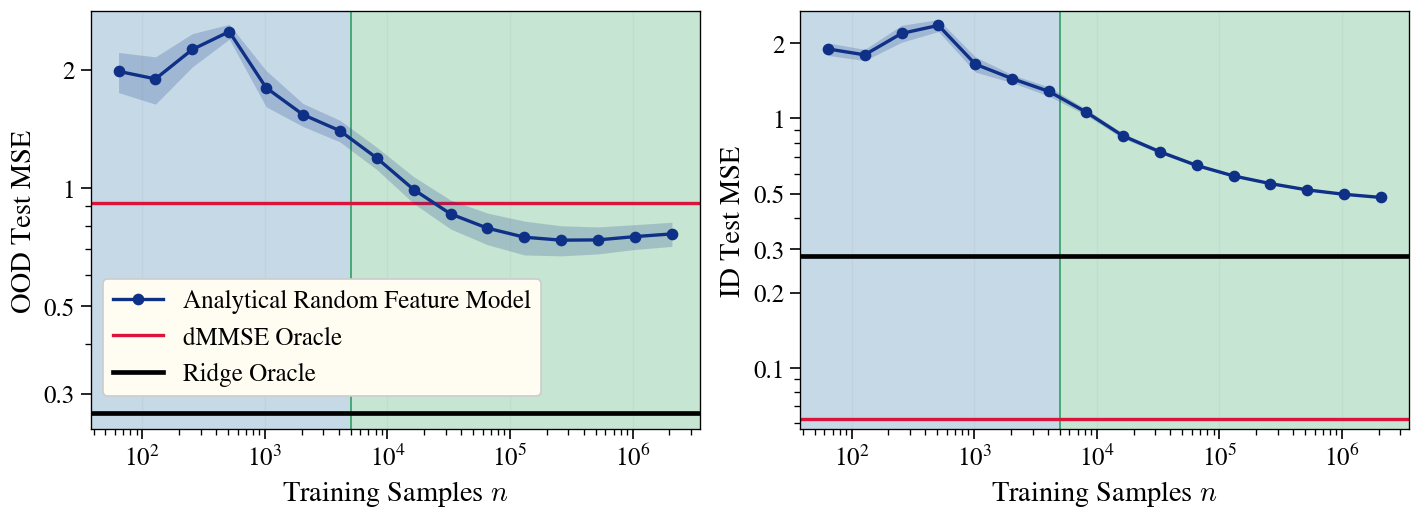

In [17]:
FIGDIR = os.path.join(RESULTPATH, "figs")
os.makedirs(FIGDIR, exist_ok=True)

have = sorted({r["T"] for _, recs in runs for r in recs})
for T in CURVE_TS:
    if T not in have:
        print(f"no records at T={T}; the loaded runs have T = {have}")
        continue
    fig, axs = plot_fig2(runs, T, SIDES, yscale=YSCALE, ylim=YLIM, band=SD_BAND, legend_loc=LEGEND_LOC,
                         xlabel=XLABEL, top_free=TOP_FREE, fontsize=FONTSIZE, t_label=False)#, t_label=T_LABEL)
    stem = os.path.join(FIGDIR, f"rf_analytic_{TAG}_T{T}_{'-'.join(SIDES)}")
    fig.savefig(stem + ".pdf", bbox_inches="tight")
    fig.savefig(stem + ".png", dpi=200, bbox_inches="tight")
    print("saved", stem + ".{pdf,png}")
    plt.show()

In [ ]:
# Where each curve bottoms out and how far it climbs after (needs transience_utils from the clone).
try:
    import transience_utils as TU
    for label, records in runs:
        print(label)
        TU.summary_table(records, sorted({r["T"] for r in records}))
except ImportError as e:
    print(f"transience_utils not importable ({e}); skipping the summary table")

Analytical Random Feature Model
   T   dMMSE  floor3  floor5   Ridge |     min       at n   final | dMMSE-min final-min
   8   0.914   0.648   0.800   0.269 |   0.734    200,000   0.759 |    +0.180    +0.025
